# Gender Detection using CNN
# By: Suchitra Thanumalayan

- **Part 1:** Data Overiew & Image Preprocessing
- **Part 2:** Predictive Model: CNN model to predict the gender (man / woman) of the person in the frame.
- **Part 3:** Evaluation & Prediction
- **Part 4:** Model Comparison Report & Data Analysis Report

In [1]:
import os, random, numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42); random.seed(42)
device = 'xpu' if torch.xpu.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
DATA = 'gender_dataset_face'
print('Device:', device)

Device: xpu


## 1. Data Overview

In [2]:
files = {c: [f for f in os.listdir(os.path.join(DATA, c)) if f.lower().endswith('.jpg')] for c in ['man', 'woman']}
for c in files: print(c, len(files[c]))

sizes = [Image.open(os.path.join(DATA, c, f)).size for c in files for f in files[c]]
w = [s[0] for s in sizes]
print('Width min/median/max:', min(w), int(np.median(w)), max(w))

man 1173
woman 1134


Width min/median/max: 24 160 2269


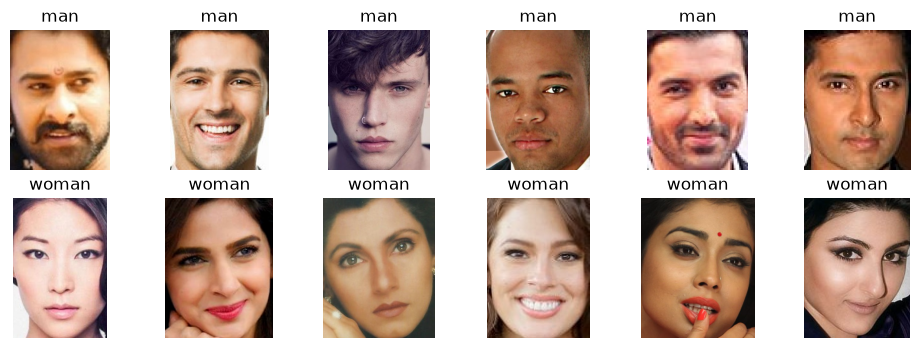

In [3]:
fig, ax = plt.subplots(2, 6, figsize=(12, 4))
for i, c in enumerate(['man', 'woman']):
    for j, f in enumerate(random.sample(files[c], 6)):
        ax[i, j].imshow(Image.open(os.path.join(DATA, c, f))); ax[i, j].set_title(c); ax[i, j].axis('off')
plt.show()

## 2. Data Analysis

        WIDTH  HEIGHT  ASPECT  BRIGHTNESS
GENDER                                   
man     159.0   214.0    0.74      125.35
woman   161.5   214.0    0.76      133.94
Images under 50px wide: 47
Duplicate images: 4 | same image in both classes: 1


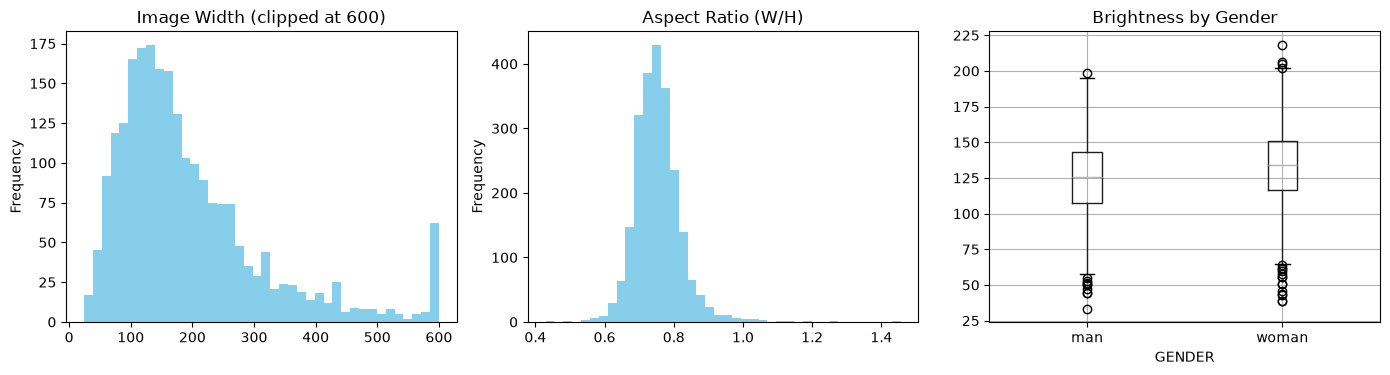

In [4]:
import hashlib, pandas as pd
rows = []
for c in files:
    for f in files[c]:
        p = os.path.join(DATA, c, f); im = Image.open(p)
        rows.append([c, im.size[0], im.size[1], np.asarray(im.convert('L')).mean(), hashlib.md5(open(p, 'rb').read()).hexdigest()])
df = pd.DataFrame(rows, columns=['GENDER', 'WIDTH', 'HEIGHT', 'BRIGHTNESS', 'MD5'])
df['ASPECT'] = df.WIDTH / df.HEIGHT
print(df.groupby('GENDER')[['WIDTH', 'HEIGHT', 'ASPECT', 'BRIGHTNESS']].median().round(2))
print('Images under 50px wide:', (df.WIDTH < 50).sum())
print('Duplicate images:', df.MD5.duplicated().sum(), '| same image in both classes:', (df.groupby('MD5').GENDER.nunique() > 1).sum())

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
df.WIDTH.clip(upper=600).plot.hist(bins=40, ax=ax[0], color='skyblue', title='Image Width (clipped at 600)')
df.ASPECT.plot.hist(bins=40, ax=ax[1], color='skyblue', title='Aspect Ratio (W/H)')
df.boxplot('BRIGHTNESS', by='GENDER', ax=ax[2]); ax[2].set_title('Brightness by Gender')
plt.suptitle(''); plt.tight_layout(); plt.show()

**Observation:**
- Median image size is about 160x214 for both genders, so image size will not give away the label.
- Most images are taller than wide (median aspect ratio ~0.75). Resizing to a 96x96 square stretches them slightly, but it does this the same way for every image.
- 47 images are under 50px wide. These low-resolution faces are harder to classify.
- Women's images are slightly brighter (median 133.9 vs 125.4). The difference is small, and colour jitter during training stops the model from relying on it.
- 4 exact duplicate files were found, and 1 identical image is stored in **both** the man and woman folders (label noise). These are too few to affect results.

## 3. Image Preprocessing
- Resize all images to 96x96
- Augmentation on training data (horizontal flip, small rotation, colour jitter) to reduce overfitting
- Convert to tensor and normalize pixel values to [-1, 1]
- Split 80% train / 20% test

In [5]:
IMG = 96
norm = transforms.Normalize([0.5]*3, [0.5]*3)
train_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.RandomHorizontalFlip(),
                               transforms.RandomRotation(10), transforms.ColorJitter(0.2, 0.2), transforms.ToTensor(), norm])
test_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), norm])

full = datasets.ImageFolder(DATA)
n_train = int(0.8 * len(full))
train_idx, test_idx = random_split(range(len(full)), [n_train, len(full) - n_train])
train_ds = torch.utils.data.Subset(datasets.ImageFolder(DATA, train_tf), list(train_idx))
test_ds  = torch.utils.data.Subset(datasets.ImageFolder(DATA, test_tf),  list(test_idx))
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=64)
classes = full.classes
print(classes, 'Train:', len(train_ds), 'Test:', len(test_ds))

['man', 'woman'] Train: 1845 Test: 462


## 4. CNN Model
4 convolution blocks (Conv -> BatchNorm -> ReLU -> MaxPool), then dropout and a dense layer with 2 outputs.

In [6]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))

model = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256),
                      nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(256, 2)).to(device)
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 30
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_dl))
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(256, eps=

In [7]:
def evaluate(dl):
    model.eval(); preds, labels = [], []
    with torch.no_grad():
        for x, y in dl:
            preds += model(x.to(device)).argmax(1).cpu().tolist(); labels += y.tolist()
    return np.array(labels), np.array(preds)

import time; start = time.time()
hist = {'train_loss': [], 'train_acc': [], 'test_acc': []}
for ep in range(EPOCHS):
    model.train(); tot, correct, n = 0, 0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        out = model(x); loss = loss_fn(out, y)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        tot += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    y_true, y_pred = evaluate(test_dl)
    hist['train_loss'].append(tot / n); hist['train_acc'].append(correct / n); hist['test_acc'].append((y_true == y_pred).mean())
    print(f"Epoch {ep+1:2d}  loss {tot/n:.3f}  train acc {correct/n:.3f}  test acc {hist['test_acc'][-1]:.3f}")
print(f'Training time: {(time.time() - start) / 60:.1f} min')

Epoch  1  loss 0.698  train acc 0.572  test acc 0.671


Epoch  2  loss 0.563  train acc 0.714  test acc 0.742


Epoch  3  loss 0.499  train acc 0.765  test acc 0.810


Epoch  4  loss 0.436  train acc 0.798  test acc 0.870


Epoch  5  loss 0.372  train acc 0.840  test acc 0.721


Epoch  6  loss 0.325  train acc 0.858  test acc 0.630


... (20 outputs left out)

Epoch 27  loss 0.051  train acc 0.979  test acc 0.970


Epoch 28  loss 0.042  train acc 0.985  test acc 0.972


Epoch 29  loss 0.042  train acc 0.988  test acc 0.972


Epoch 30  loss 0.051  train acc 0.983  test acc 0.972
Training time: 6.1 min


## 5. Evaluation

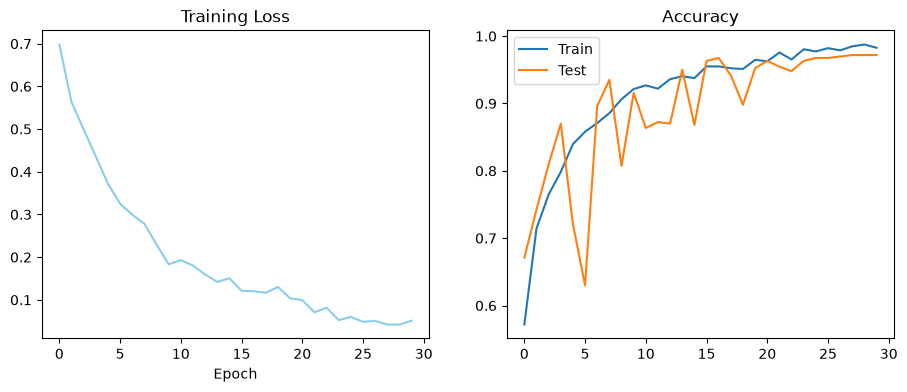

              precision    recall  f1-score   support

         man      0.978     0.966     0.972       235
       woman      0.965     0.978     0.972       227

    accuracy                          0.972       462
   macro avg      0.972     0.972     0.972       462
weighted avg      0.972     0.972     0.972       462



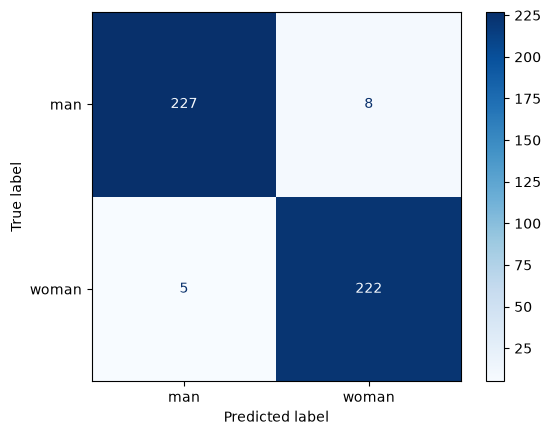

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist['train_loss'], color='skyblue'); ax[0].set_title('Training Loss'); ax[0].set_xlabel('Epoch')
ax[1].plot(hist['train_acc'], label='Train'); ax[1].plot(hist['test_acc'], label='Test'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

y_true, y_pred = evaluate(test_dl)
print(classification_report(y_true, y_pred, target_names=classes, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(cmap='Blues'); plt.show()

**Observation:** The CNN gets **97.2% accuracy** on 462 unseen test images. Man: precision 0.978 / recall 0.966; Woman: precision 0.965 / recall 0.978, so both genders are predicted equally well. Only 13 test images are misclassified (8 men, 5 women). Train (98.3%) and test (97.2%) accuracy are close, so the model is not overfitting much. Augmentation and dropout helped with that. Test accuracy jumps around in early epochs but settles once the learning rate drops.

## 6. Predict Gender on New Images

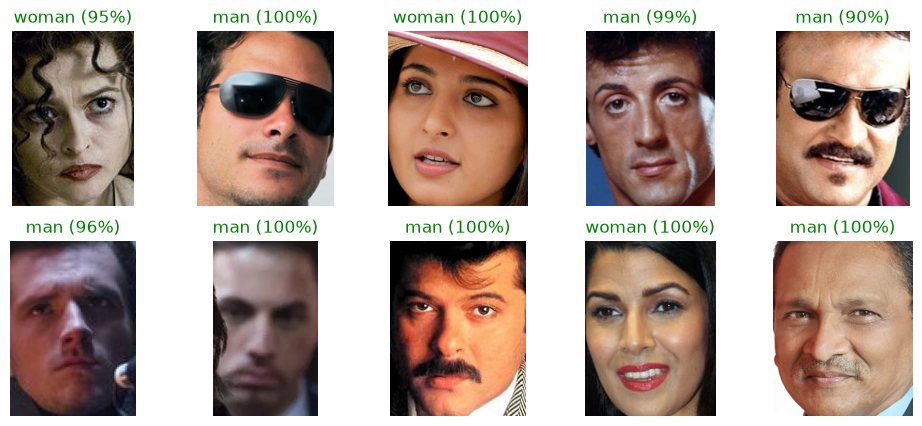

In [9]:
torch.save(model.state_dict(), 'gender_cnn.pth')

def predict(path):
    model.eval()
    img = Image.open(path).convert('RGB')
    with torch.no_grad():
        p = torch.softmax(model(test_tf(img).unsqueeze(0).to(device)), 1)[0].cpu()
    return classes[p.argmax()], p.max().item()

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for a, i in zip(ax.flat, random.sample(list(test_idx), 10)):
    path, true = full.samples[i]
    label, conf = predict(path)
    a.imshow(Image.open(path)); a.axis('off')
    a.set_title(f'{label} ({conf:.0%})', color='green' if label == classes[true] else 'red')
plt.show()

## Conclusion
- **Preprocessing:** removed non-image files, resized faces of very different sizes (24px to 2269px wide) to 96x96, normalized pixels, and augmented the training set with flips, rotation and colour jitter.
- **Model:** a simple 4-block CNN trained from scratch for 30 epochs reaches **97.2% test accuracy**, with balanced precision and recall for both classes.
- The model is saved as `gender_cnn.pth`, and `predict(path)` returns the gender and confidence for any face image.
- **Limitation:** the model expects a cropped face. For full photos, a face detector (e.g. OpenCV Haar cascade) should crop the face first.

# Data Analysis Report
| Item | Finding |
|---|---|
| Dataset | 2,307 cropped face images (JPG, RGB) in 2 folders |
| Class balance | Man 1,173 (50.8%) / Woman 1,134 (49.2%), balanced, so no resampling needed |
| Non-image files | `.DS_Store` in each folder, ignored |
| Image size | Width 24 to 2,269 px, median ~160x214 for both classes |
| Aspect ratio | Median ~0.75 (portrait) for both classes |
| Low resolution | 47 images under 50 px wide |
| Brightness | Woman 133.9 vs Man 125.4 (median), small difference |
| Duplicates | 4 duplicate files, 1 image labelled as both genders |
| Preprocessing done | Resize to 96x96, normalize to [-1, 1], flip/rotate/colour-jitter augmentation on training images, 80/20 split (1,845 / 462) |

# Model Report
| Item | Value |
|---|---|
| Model | Custom CNN: 4 x (Conv3x3, BatchNorm, ReLU, MaxPool), then global avg pool, Dropout 0.5, Linear(256 to 2) |
| Trainable parameters | 389,890 |
| Input | 96x96 RGB |
| Training | Adam + OneCycle LR (max 3e-3), batch 32, 30 epochs, cross-entropy loss |
| Hardware / time | Intel Arc GPU (XPU), ~6 min |
| Train accuracy | 98.3% |
| **Test accuracy** | **97.2%** (449 / 462 correct) |
| Man | precision 0.978, recall 0.966, F1 0.972 |
| Woman | precision 0.965, recall 0.978, F1 0.972 |
| Errors | 13 (8 men predicted as women, 5 women predicted as men) |

**Summary:** The CNN predicts both genders equally well (F1 0.972 each), and the gap between train and test accuracy is small (1.1 points), so the model generalizes well. It is light (~390k parameters), so it can run quickly even on a CPU.

## Challenges Faced

| # | Challenge | Technique Used | Reason |
|---|---|---|---|
| 1 | Hidden `.DS_Store` files crashed image loading | Read only `.jpg` files (ImageFolder already skips non-images) | Avoid errors from non-image files |
| 2 | Image sizes vary from 24px to 2,269px | Resize all images to 96x96 | The CNN needs a fixed input size |
| 3 | Small dataset (~1,850 training images) can overfit | Augmentation (flip, rotation, colour jitter), BatchNorm, Dropout 0.5 | Gives more variety and regularization; train/test gap is only 1.1 points |
| 4 | Small brightness difference between classes | Colour jitter augmentation | Stops the model from using lighting as a shortcut |
| 5 | Test accuracy jumped around in early epochs | OneCycle learning rate schedule | High LR early for fast learning, low LR at the end for stable results |
| 6 | Model only works on cropped faces | Documented. Use a face detector to crop full photos | Training images are face crops only |